In [1]:
import kagglehub

path = kagglehub.dataset_download("mostafaabla/garbage-classification")

100%|██████████| 239M/239M [00:02<00:00, 109MB/s]

Extracting files...


In [2]:

# Duplicate-aware split using pHash (Hamming distance <= 4)
# Run after the KaggleHub dataset download cell.

from pathlib import Path
from collections import defaultdict
import os
import sys
import subprocess
import pandas as pd
import numpy as np

try:
    from PIL import Image
    import imagehash
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "ImageHash"]
    )
    from PIL import Image
    import imagehash

from sklearn.model_selection import StratifiedGroupKFold

# 1. Find the dataset root from the variable created by your kagglehub cell.
# If your variable has a different name, set DATASET_ROOT manually.
DATASET_ROOT = None
for var_name in ("path", "dataset_path", "data_dir", "dataset_dir"):
    if var_name in globals():
        candidate = Path(str(globals()[var_name]))
        if candidate.exists():
            DATASET_ROOT = candidate
            break

if DATASET_ROOT is None:
    raise ValueError(
        "Set DATASET_ROOT = Path('YOUR_KAGGLEHUB_DATASET_PATH') "
        "using the path printed by your existing download cell."
    )

print("Dataset root:", DATASET_ROOT)

# 2. Recognise the 12 dataset classes from the parent folder.
CLASSES = {
    "battery", "biological", "brown-glass", "cardboard", "clothes",
    "green-glass", "metal", "paper", "plastic", "shoes", "trash",
    "white-glass"
}
EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def normalise_class(s):
    return s.strip().lower().replace("_", "-").replace(" ", "-")

records = []
for p in DATASET_ROOT.rglob("*"):
    if p.is_file() and p.suffix.lower() in EXTS:
        label = normalise_class(p.parent.name)
        if label in CLASSES:
            records.append({"path": str(p), "label": label})

all_df = pd.DataFrame(records).drop_duplicates("path").reset_index(drop=True)

if all_df.empty:
    raise ValueError(
        "No images found in recognised class folders. "
        "Inspect DATASET_ROOT and the dataset folder structure before proceeding."
    )

print("Images found:", len(all_df))
print("Classes found:", sorted(all_df["label"].unique()))
print(all_df["label"].value_counts().sort_index())

if set(all_df["label"].unique()) != CLASSES:
    raise ValueError("Not all 12 expected classes were found. Check the folder structure.")

# 3. Compute 64-bit perceptual hashes.
hashes = []
bad_files = []

for i, p in enumerate(all_df["path"]):
    try:
        with Image.open(p) as im:
            hashes.append(int(str(imagehash.phash(im.convert("RGB"))), 16))
    except Exception as e:
        hashes.append(None)
        bad_files.append((p, str(e)))

if bad_files:
    raise RuntimeError(
        f"{len(bad_files)} images could not be hashed. "
        "Inspect bad_files before making a new split."
    )

print("pHash computed for every image.")

# 4. BK-tree: efficiently find previous hashes within Hamming distance 4.
def hamming(a, b):
    return (a ^ b).bit_count()

class BKTree:
    def __init__(self):
        self.root = None

    def add(self, value, index):
        if self.root is None:
            self.root = [value, [index], {}]
            return

        node = self.root
        while True:
            d = hamming(value, node[0])
            if d == 0:
                node[1].append(index)
                return
            if d not in node[2]:
                node[2][d] = [value, [index], {}]
                return
            node = node[2][d]

    def query(self, value, radius):
        found = []
        if self.root is None:
            return found

        stack = [self.root]
        while stack:
            node = stack.pop()
            d = hamming(value, node[0])
            if d <= radius:
                found.extend((j, d) for j in node[1])
            low, high = d - radius, d + radius
            for edge, child in node[2].items():
                if low <= edge <= high:
                    stack.append(child)
        return found

# 5. Union images connected by pHash distance <= 4.
# Connected components are kept together, including transitive matches.
n = len(all_df)
parent = list(range(n))
rank = [0] * n

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(a, b):
    a, b = find(a), find(b)
    if a == b:
        return
    if rank[a] < rank[b]:
        a, b = b, a
    parent[b] = a
    if rank[a] == rank[b]:
        rank[a] += 1

tree = BKTree()
near_pairs = []

for i, hv in enumerate(hashes):
    for j, dist in tree.query(hv, radius=4):
        union(i, j)
        near_pairs.append((j, i, dist))
    tree.add(hv, i)

all_df["group_id"] = [find(i) for i in range(n)]

group_sizes = all_df.groupby("group_id").size()
print("Images:", n)
print("Duplicate/near-duplicate groups (size > 1):",
      int((group_sizes > 1).sum()))
print("Images in those groups:",
      int(group_sizes[group_sizes > 1].sum()))
print("Near-match pairs at Hamming distance <= 4:", len(near_pairs))

# Preserve the detailed pairs for manual audit.
pairs_df = pd.DataFrame([
    {
        "image_a": all_df.iloc[a]["path"],
        "label_a": all_df.iloc[a]["label"],
        "image_b": all_df.iloc[b]["path"],
        "label_b": all_df.iloc[b]["label"],
        "hamming_distance": d
    }
    for a, b, d in near_pairs
])
pairs_df.to_csv("/content/phash_near_duplicate_pairs.csv", index=False)

# 6. Make approximately 80/10/10 grouped, stratified splits.
# Test = one fold out of 10; validation = one fold out of the remaining 9.
y = all_df["label"].to_numpy()
groups = all_df["group_id"].to_numpy()
indices = np.arange(n)

outer = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
trainval_rel, test_rel = next(outer.split(indices, y, groups))
trainval_idx = indices[trainval_rel]
test_idx = indices[test_rel]

inner = StratifiedGroupKFold(n_splits=9, shuffle=True, random_state=43)
train_rel, val_rel = next(
    inner.split(
        trainval_idx,
        y[trainval_idx],
        groups[trainval_idx]
    )
)
train_idx = trainval_idx[train_rel]
val_idx = trainval_idx[val_rel]

all_df["split"] = ""
all_df.loc[train_idx, "split"] = "train"
all_df.loc[val_idx, "split"] = "validation"
all_df.loc[test_idx, "split"] = "test"

# 7. Mandatory leakage check: no group may occur in multiple splits.
split_counts = all_df.groupby("group_id")["split"].nunique()
assert split_counts.max() == 1, "ERROR: a duplicate group crosses splits!"

print("\nSplit sizes:")
print(all_df["split"].value_counts())
print("\nClass distribution by split:")
print(pd.crosstab(all_df["label"], all_df["split"]))

all_df.to_csv("/content/duplicate_aware_split.csv", index=False)
print("\nSaved:")
print("/content/duplicate_aware_split.csv")
print("/content/phash_near_duplicate_pairs.csv")


Dataset root: /root/.cache/kagglehub/datasets/mostafaabla/garbage-classification/versions/1
Images found: 15515
Classes found: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
label
battery         945
biological      985
brown-glass     607
cardboard       891
clothes        5325
green-glass     629
metal           769
paper          1050
plastic         865
shoes          1977
trash           697
white-glass     775
Name: count, dtype: int64
pHash computed for every image.
Images: 15515
Duplicate/near-duplicate groups (size > 1): 163
Images in those groups: 365
Near-match pairs at Hamming distance <= 4: 253

Split sizes:
split
train         12415
validation     1553
test           1547
Name: count, dtype: int64

Class distribution by split:
split        test  train  validation
label                               
battery        94    757          94
biological     98    789          98
brown-

In [3]:
import pandas as pd

split_file = "/content/duplicate_aware_split.csv"
pairs_file = "/content/phash_near_duplicate_pairs.csv"

df = pd.read_csv(split_file)
pairs = pd.read_csv(pairs_file)

print("Split manifest columns:", df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

print("\nNear-duplicate report columns:", pairs.columns.tolist())
display(pairs.head())

print("\nImages per split:")
print(df["split"].value_counts())

print("\nUnique classes per split:")
print(df.groupby("split")["label"].nunique())

print("\nMissing values:")
print(df.isna().sum())

Split manifest columns: ['path', 'label', 'group_id', 'split']

First five rows:


,path,label,group_id,split
0,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,0,train
1,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,1,train
2,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,2,validation
3,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,3,test
4,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,4,test



Near-duplicate report columns: ['image_a', 'label_a', 'image_b', 'label_b', 'hamming_distance']


,image_a,label_a,image_b,label_b,hamming_distance
0,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,4
1,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,4
2,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,4
3,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,4
4,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,/root/.cache/kagglehub/datasets/mostafaabla/ga...,clothes,4



Images per split:
split
train         12415
validation     1553
test           1547
Name: count, dtype: int64

Unique classes per split:
split
test          12
train         12
validation    12
Name: label, dtype: int64

Missing values:
path        0
label       0
group_id    0
split       0
dtype: int64


In [4]:
import pandas as pd

manifest_path = "/content/duplicate_aware_split.csv"
pairs_path = "/content/phash_near_duplicate_pairs.csv"

df = pd.read_csv(manifest_path)
pairs = pd.read_csv(pairs_path)

# 1. Check whether any group_id occurs in multiple splits
splits_per_group = df.groupby("group_id")["split"].nunique()
leaked_groups = splits_per_group[splits_per_group > 1]

print("=== GROUP LEAKAGE CHECK ===")
print("Total groups:", df["group_id"].nunique())
print("Groups appearing in multiple splits:", len(leaked_groups))

# 2. Check duplicate pairs that cross split boundaries
path_to_split = df.set_index("path")["split"].to_dict()

pairs["split_a"] = pairs["image_a"].map(path_to_split)
pairs["split_b"] = pairs["image_b"].map(path_to_split)

cross_split_pairs = pairs[
    pairs["split_a"] != pairs["split_b"]
]

print("\n=== NEAR-DUPLICATE PAIR CHECK ===")
print("Near-duplicate pairs:", len(pairs))
print("Pairs crossing splits:", len(cross_split_pairs))

# 3. Check near-duplicate pairs with conflicting labels
conflicting_pairs = pairs[pairs["label_a"] != pairs["label_b"]]

print("\n=== LABEL CONFLICT CHECK ===")
print("Pairs with different labels:", len(conflicting_pairs))

if len(conflicting_pairs):
    display(conflicting_pairs.head(20))

# 4. Overall status
passed = (
    len(leaked_groups) == 0
    and len(cross_split_pairs) == 0
)

print("\n=== RESULT ===")
if passed:
    print("PASS: No detected group leakage or cross-split near-duplicate pairs.")
else:
    print("FAIL: Investigate group assignment before training.")

=== GROUP LEAKAGE CHECK ===
Total groups: 15313
Groups appearing in multiple splits: 0

=== NEAR-DUPLICATE PAIR CHECK ===
Near-duplicate pairs: 253
Pairs crossing splits: 0

=== LABEL CONFLICT CHECK ===
Pairs with different labels: 59


,image_a,label_a,image_b,label_b,hamming_distance,split_a,split_b
67,/root/.cache/kagglehub/datasets/mostafaabla/ga...,trash,/root/.cache/kagglehub/datasets/mostafaabla/ga...,green-glass,4,train,train
75,/root/.cache/kagglehub/datasets/mostafaabla/ga...,trash,/root/.cache/kagglehub/datasets/mostafaabla/ga...,green-glass,4,validation,validation
76,/root/.cache/kagglehub/datasets/mostafaabla/ga...,trash,/root/.cache/kagglehub/datasets/mostafaabla/ga...,green-glass,4,validation,validation
77,/root/.cache/kagglehub/datasets/mostafaabla/ga...,trash,/root/.cache/kagglehub/datasets/mostafaabla/ga...,green-glass,4,validation,validation
78,/root/.cache/kagglehub/datasets/mostafaabla/ga...,trash,/root/.cache/kagglehub/datasets/mostafaabla/ga...,green-glass,4,validation,validation
107,/root/.cache/kagglehub/datasets/mostafaabla/ga...,trash,/root/.cache/kagglehub/datasets/mostafaabla/ga...,green-glass,4,validation,validation
109,/root/.cache/kagglehub/datasets/mostafaabla/ga...,trash,/root/.cache/kagglehub/datasets/mostafaabla/ga...,green-glass,4,train,train
110,/root/.cache/kagglehub/datasets/mostafaabla/ga...,trash,/root/.cache/kagglehub/datasets/mostafaabla/ga...,green-glass,4,validation,validation
111,/root/.cache/kagglehub/datasets/mostafaabla/ga...,trash,/root/.cache/kagglehub/datasets/mostafaabla/ga...,green-glass,2,validation,validation
112,/root/.cache/kagglehub/datasets/mostafaabla/ga...,trash,/root/.cache/kagglehub/datasets/mostafaabla/ga...,green-glass,4,validation,validation



=== RESULT ===
PASS: No detected group leakage or cross-split near-duplicate pairs.


Conflicting pairs: 59
Saved: /content/phash_label_conflicts.csv


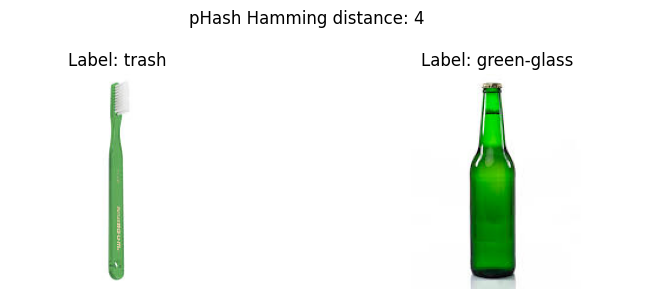

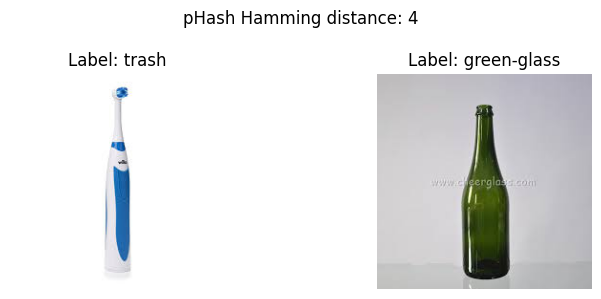

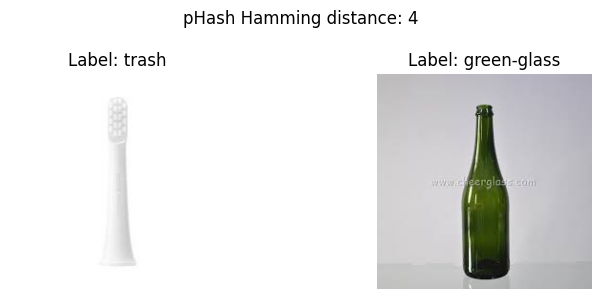

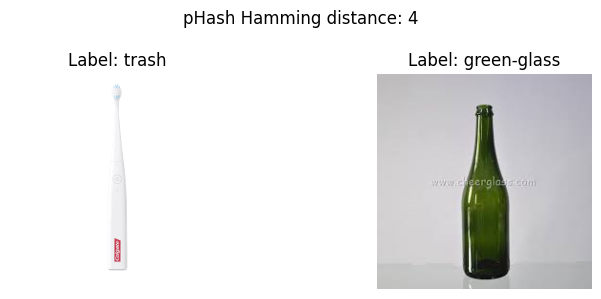

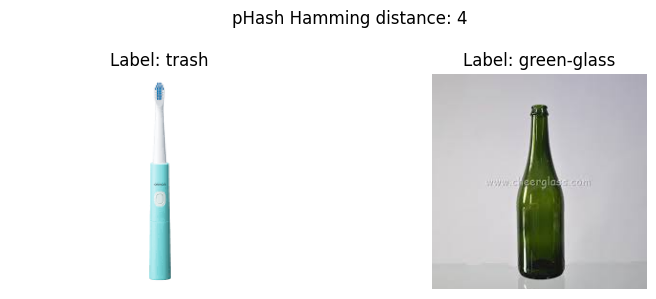

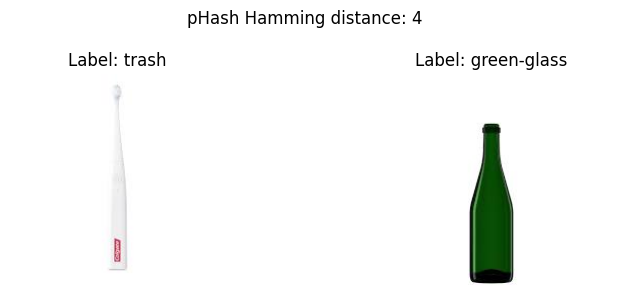

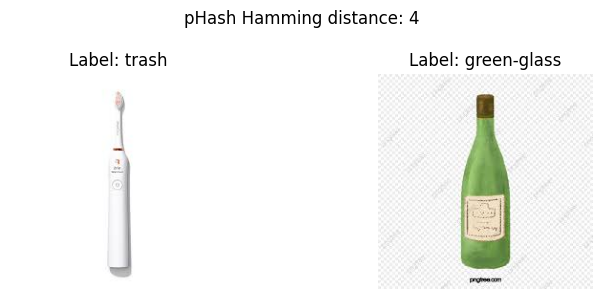

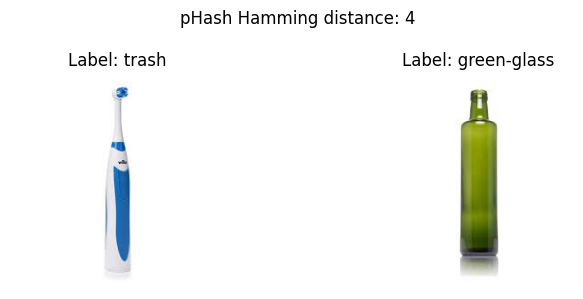

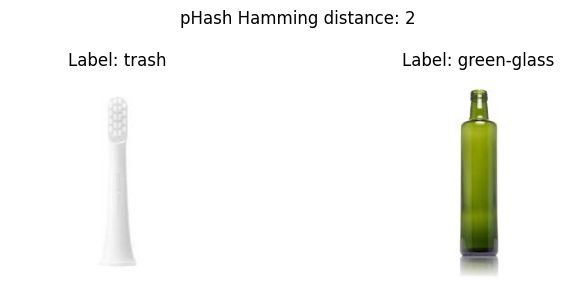

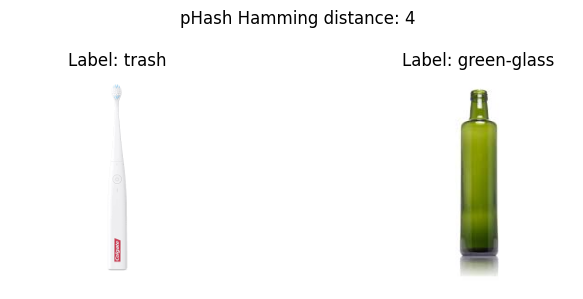

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

pairs = pd.read_csv(
    "/content/phash_near_duplicate_pairs.csv"
)

conflicts = pairs[pairs["label_a"] != pairs["label_b"]].copy()

conflicts.to_csv(
    "/content/phash_label_conflicts.csv",
    index=False
)

print("Conflicting pairs:", len(conflicts))
print("Saved: /content/phash_label_conflicts.csv")

# Inspect the first 10 pairs visually
for _, row in conflicts.head(10).iterrows():
    fig, axes = plt.subplots(1, 2, figsize=(8, 3))

    for ax, path, label in [
        (axes[0], row["image_a"], row["label_a"]),
        (axes[1], row["image_b"], row["label_b"]),
    ]:
        try:
            with Image.open(path) as img:
                ax.imshow(img.convert("RGB"))
            ax.set_title(f"Label: {label}")
            ax.axis("off")
        except Exception as e:
            ax.set_title(f"Could not load image: {e}")
            ax.axis("off")

    distance = row["hamming_distance"]
    fig.suptitle(f"pHash Hamming distance: {distance}")
    plt.tight_layout()
    plt.show()

In [6]:
import os
import json
import pandas as pd
import tensorflow as tf

# Load the duplicate-aware pHash split
manifest = pd.read_csv("/content/duplicate_aware_split.csv")

# Preserve the model's existing class order if already defined
if "class_names" in globals():
    expected_classes = list(class_names)
else:
    expected_classes = sorted(manifest["label"].unique())

# Create fresh dataframes; do not reuse the old MD5 split
train_df = (
    manifest[manifest["split"] == "train"]
    .drop(columns=["split"])
    .reset_index(drop=True)
)
val_df = (
    manifest[manifest["split"] == "validation"]
    .drop(columns=["split"])
    .reset_index(drop=True)
)
test_df = (
    manifest[manifest["split"] == "test"]
    .drop(columns=["split"])
    .reset_index(drop=True)
)

# Verify class coverage and file existence
assert set(train_df["label"]) == set(expected_classes)
assert set(val_df["label"]) == set(expected_classes)
assert set(test_df["label"]) == set(expected_classes)

for name, part in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    missing = [p for p in part["path"] if not os.path.isfile(p)]
    assert not missing, f"{name}: {len(missing)} files missing"
    print(f"{name}: {len(part)} images, {part['label'].nunique()} classes")

print("\nAll paths and class coverage verified.")

train: 12415 images, 12 classes
validation: 1553 images, 12 classes
test: 1547 images, 12 classes

All paths and class coverage verified.


In [7]:
import pandas as pd

# Load the verified split manifest
manifest = pd.read_csv("/content/duplicate_aware_split.csv")

# Define the 12 classes in a deterministic order
class_names = sorted(manifest["label"].unique().tolist())

print("Number of classes:", len(class_names))
print("Class names:", class_names)

assert len(class_names) == 12, "Expected exactly 12 classes"

Number of classes: 12
Class names: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


In [8]:
SEED = 42
print("Random seed:", SEED)

Random seed: 42


In [9]:

import numpy as np
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

# Keep the same class-to-index mapping throughout training and evaluation.
class_to_idx = {name: i for i, name in enumerate(class_names)}

for name, part in [
    ("train", train_df),
    ("validation", val_df),
    ("test", test_df),
]:
    unknown = set(part["label"]) - set(class_to_idx)
    assert not unknown, f"Unexpected labels in {name}: {unknown}"

def load(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(
        img, channels=3, expand_animations=False
    )
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)
    img.set_shape((224, 224, 3))
    return img, label

def make_ds(d, training=False):
    paths = d["path"].astype(str).values
    labels = d["label"].map(class_to_idx).to_numpy(dtype=np.int32)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            len(d),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    return (
        ds.map(load, num_parallel_calls=AUTOTUNE)
          .batch(BATCH)
          .prefetch(AUTOTUNE)
    )

train_ds = make_ds(train_df, training=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

# Verify one batch
images, labels = next(iter(train_ds))

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))
print("Image batch shape:", images.shape)
print("Image dtype:", images.dtype)
print("Label batch shape:", labels.shape)
print("Class mapping:", class_to_idx)


Train images: 12415
Validation images: 1553
Test images: 1547
Image batch shape: (32, 224, 224, 3)
Image dtype: <dtype: 'float32'>
Label batch shape: (32,)
Class mapping: {'battery': 0, 'biological': 1, 'brown-glass': 2, 'cardboard': 3, 'clothes': 4, 'green-glass': 5, 'metal': 6, 'paper': 7, 'plastic': 8, 'shoes': 9, 'trash': 10, 'white-glass': 11}


In [10]:
import pandas as pd

manifest = pd.read_csv("/content/duplicate_aware_split.csv")

expected = manifest["split"].value_counts().to_dict()
actual = {
    "train": len(train_df),
    "validation": len(val_df),
    "test": len(test_df),
}

print("Manifest counts:", expected)
print("Dataframe counts:", actual)

assert actual == expected, "Dataframes do not match manifest counts"

assert (
    set(train_df["path"]).isdisjoint(val_df["path"])
    and set(train_df["path"]).isdisjoint(test_df["path"])
    and set(val_df["path"]).isdisjoint(test_df["path"])
), "Image paths overlap across splits"

print("PASS: Dataframes match the manifest; no path overlap.")

Manifest counts: {'train': 12415, 'validation': 1553, 'test': 1547}
Dataframe counts: {'train': 12415, 'validation': 1553, 'test': 1547}
PASS: Dataframes match the manifest; no path overlap.


In [14]:
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)
print("Keras layers and models imported successfully.")

TensorFlow version: 2.21.0
Keras layers and models imported successfully.


In [17]:
def build_model():
    aug = tf.keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
    ], name="data_augmentation")
    base = tf.keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inp = layers.Input(shape=(224, 224, 3))
    x = aug(inp)
    x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
    x = base(x, training=False)          # keeps BatchNorm in inference mode, also during fine-tuning
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out), base

def evaluate(model, d, ds, name):
    probs = model.predict(ds, verbose=0)
    yp = probs.argmax(1); yt = d['label'].values
    res = dict(model=name,
               accuracy=accuracy_score(yt, yp),
               macro_f1=f1_score(yt, yp, average='macro'),
               weighted_f1=f1_score(yt, yp, average='weighted'))
    return res, yp

def new_callbacks():
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)]

tf.keras.backend.clear_session()
model, base_model = build_model()      # fresh ImageNet weights, nothing carried over from the old run

In [18]:
NUM_CLASSES = len(class_names)

assert NUM_CLASSES == 12
assert model.output_shape[-1] == NUM_CLASSES

print("Number of classes:", NUM_CLASSES)
print("Class order:", class_names)
print("Model output shape:", model.output_shape)

Number of classes: 12
Class order: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
Model output shape: (None, 12)


In [19]:
def evaluate(model, d, ds, name):
    probs = model.predict(ds, verbose=0)
    yp = probs.argmax(axis=1)

    # Convert string labels to model class indices
    yt = d["label"].map(class_to_idx).to_numpy(dtype="int32")

    assert len(yt) == len(yp), (
        f"Prediction count mismatch: {len(yp)} predictions "
        f"for {len(yt)} labels"
    )

    res = dict(
        model=name,
        accuracy=accuracy_score(yt, yp),
        macro_f1=f1_score(
            yt, yp, average="macro", zero_division=0
        ),
        weighted_f1=f1_score(
            yt, yp, average="weighted", zero_division=0
        ),
    )

    return res, yp

In [21]:
from sklearn.metrics import accuracy_score, f1_score
print("Evaluation metrics imported successfully.")

Evaluation metrics imported successfully.


In [20]:

# Stage 1: train the classification head with a frozen backbone

import os

os.makedirs("outputs", exist_ok=True)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

h1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=new_callbacks(),
)

# Use validation data for model selection; keep test set untouched
res_frozen_val, pred_frozen_val = evaluate(
    model, val_df, val_ds, "Frozen MobileNetV2"
)

print("Frozen validation:", res_frozen_val)

model.save_weights("outputs/frozen.weights.h5")
print("Saved frozen-stage weights.")


Epoch 1/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 41s 77ms/step - accuracy: 0.8149 - loss: 0.6022 - val_accuracy: 0.9169 - val_loss: 0.2739
Epoch 2/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - accuracy: 0.9049 - loss: 0.2992 - val_accuracy: 0.9253 - val_loss: 0.2350
Epoch 3/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 27s 70ms/step - accuracy: 0.9188 - loss: 0.2562 - val_accuracy: 0.9285 - val_loss: 0.2147
Epoch 4/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 30s 76ms/step - accuracy: 0.9238 - loss: 0.2409 - val_accuracy: 0.9253 - val_loss: 0.2273
Epoch 5/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 27s 70ms/step - accuracy: 0.9280 - loss: 0.2179 - val_accuracy: 0.9337 - val_loss: 0.2048
Epoch 6/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 27s 70ms/step - accuracy: 0.9306 - loss: 0.2059 - val_accuracy: 0.9363 - val_loss: 0.1970
Epoch 7/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 30s 76ms/step - accuracy: 0.9352 - loss: 0.2053 - val_accuracy: 0.9337 - val_loss: 0.2106
Epoch 8/10
388/388 ━━━━━━━━━━━━━━━━━━━━ 39s 70ms/step - accuracy: 0.9349 - loss: 0.1939 - 

NameError: name 'accuracy_score' is not defined

In [22]:
res_frozen_val, pred_frozen_val = evaluate(
    model, val_df, val_ds, "Frozen MobileNetV2"
)

print("Frozen validation:", res_frozen_val)

Frozen validation: {'model': 'Frozen MobileNetV2', 'accuracy': 0.9362524146812621, 'macro_f1': 0.9144075226826751, 'weighted_f1': 0.9360013081363115}


In [23]:
import os
os.makedirs("outputs", exist_ok=True)
model.save_weights("outputs/frozen.weights.h5")
print("Stage 1 weights saved.")

Stage 1 weights saved.


In [24]:
base_model.trainable = True

for layer in base_model.layers[:100]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

FT_EPOCHS = 5

h2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=FT_EPOCHS,
    callbacks=new_callbacks()
)

Epoch 1/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 63s 117ms/step - accuracy: 0.8847 - loss: 0.3501 - val_accuracy: 0.9433 - val_loss: 0.1802
Epoch 2/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - accuracy: 0.9101 - loss: 0.2732 - val_accuracy: 0.9433 - val_loss: 0.1785
Epoch 3/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 43s 112ms/step - accuracy: 0.9220 - loss: 0.2380 - val_accuracy: 0.9433 - val_loss: 0.1751
Epoch 4/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 82s 112ms/step - accuracy: 0.9327 - loss: 0.2107 - val_accuracy: 0.9427 - val_loss: 0.1702
Epoch 5/5
388/388 ━━━━━━━━━━━━━━━━━━━━ 42s 109ms/step - accuracy: 0.9359 - loss: 0.1868 - val_accuracy: 0.9453 - val_loss: 0.1663


In [25]:
res_ft_val, pred_ft_val = evaluate(
    model, val_df, val_ds, "Fine-tuned MobileNetV2"
)

print("Stage 2 validation:", res_ft_val)

model.save_weights("outputs/finetuned.weights.h5")

Stage 2 validation: {'model': 'Fine-tuned MobileNetV2', 'accuracy': 0.9452672247263362, 'macro_f1': 0.9211434233581749, 'weighted_f1': 0.9454659585520176}


In [27]:
import pandas as pd

comparison = pd.DataFrame([
    res_frozen_val,
    res_ft_val
])

print(comparison.to_string(index=False))

                 model  accuracy  macro_f1  weighted_f1
    Frozen MobileNetV2  0.936252  0.914408     0.936001
Fine-tuned MobileNetV2  0.945267  0.921143     0.945466


In [28]:
res_ft_test, pred_ft_test = evaluate(
    model, test_df, test_ds, "Fine-tuned MobileNetV2"
)

print("FINAL TEST RESULTS:", res_ft_test)

FINAL TEST RESULTS: {'model': 'Fine-tuned MobileNetV2', 'accuracy': 0.9541047188106012, 'macro_f1': 0.9336031062011725, 'weighted_f1': 0.9545495185906848}


Duplicate-aware MobileNetV2 results
     split                  model  accuracy  macro_f1  weighted_f1
validation     Frozen MobileNetV2    0.9363    0.9144       0.9360
validation Fine-tuned MobileNetV2    0.9453    0.9211       0.9455
      test Fine-tuned MobileNetV2    0.9541    0.9336       0.9545

Saved: outputs/results_table.csv


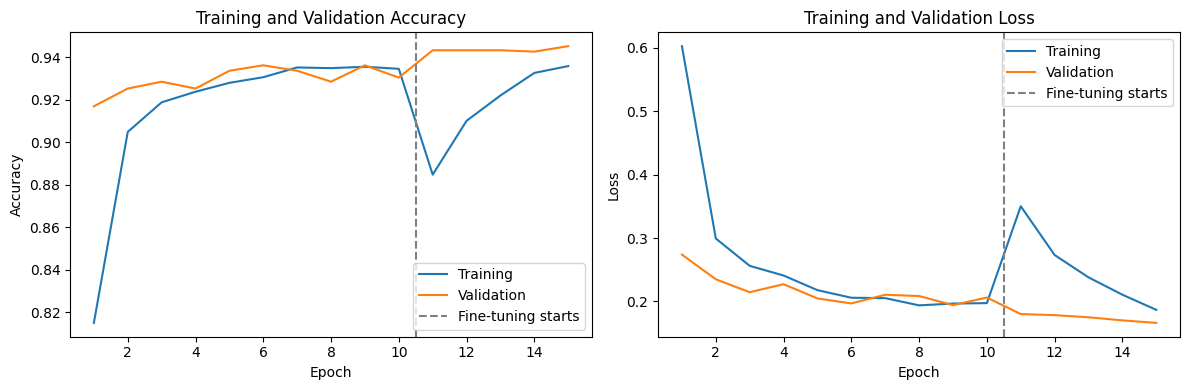

Saved: outputs/learning_curves.png


In [29]:

import os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("outputs", exist_ok=True)

# 1. Results table: validation metrics for model selection,
#    final test metrics for the selected fine-tuned model.
rows = [
    {**res_frozen_val, "split": "validation"},
    {**res_ft_val, "split": "validation"},
    {**res_ft_test, "split": "test"},
]

table = pd.DataFrame(rows)

# Put split and model first
cols = ["split", "model"] + [
    c for c in table.columns if c not in ["split", "model"]
]
table = table[cols]

print("Duplicate-aware MobileNetV2 results")
print(table.round(4).to_string(index=False))

table.to_csv("outputs/results_table.csv", index=False)
print("\nSaved: outputs/results_table.csv")


# 2. Learning curves: Stage 1 frozen backbone + Stage 2 fine-tuning
acc = h1.history["accuracy"] + h2.history["accuracy"]
vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
loss = h1.history["loss"] + h2.history["loss"]
vloss = h1.history["val_loss"] + h2.history["val_loss"]

ep1 = len(h1.history["loss"])
epochs = range(1, len(acc) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, acc, label="Training")
axes[0].plot(epochs, vacc, label="Validation")
axes[0].axvline(
    ep1 + 0.5, linestyle="--", color="gray",
    label="Fine-tuning starts"
)
axes[0].set_title("Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(epochs, loss, label="Training")
axes[1].plot(epochs, vloss, label="Validation")
axes[1].axvline(
    ep1 + 0.5, linestyle="--", color="gray",
    label="Fine-tuning starts"
)
axes[1].set_title("Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig("outputs/learning_curves.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved: outputs/learning_curves.png")


Classification Report — Fine-tuned MobileNetV2 (Test Set)
              precision    recall  f1-score   support

     battery     0.9271    0.9468    0.9368        94
  biological     0.9800    1.0000    0.9899        98
 brown-glass     0.9821    0.9167    0.9483        60
   cardboard     0.9651    0.9121    0.9379        91
     clothes     0.9981    0.9924    0.9953       529
 green-glass     0.9219    0.9672    0.9440        61
       metal     0.7912    0.9351    0.8571        77
       paper     0.9700    0.9151    0.9417       106
     plastic     0.8478    0.9070    0.8764        86
       shoes     0.9697    0.9648    0.9673       199
       trash     0.9846    0.9275    0.9552        69
 white-glass     0.8767    0.8312    0.8533        77

    accuracy                         0.9541      1547
   macro avg     0.9345    0.9347    0.9336      1547
weighted avg     0.9562    0.9541    0.9545      1547



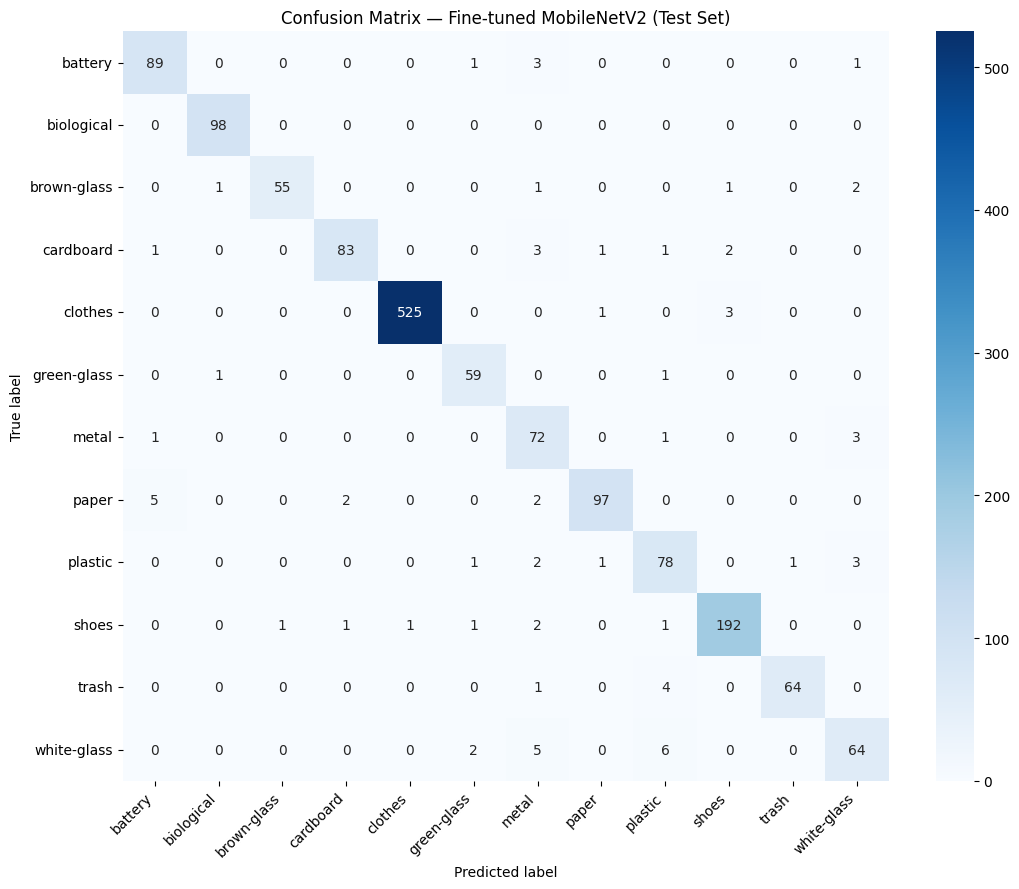

Saved: outputs/confusion_matrix.png and outputs/confusion_matrix.csv

Top 5 most frequent misclassifications:
Actual: white-glass -> Predicted: plastic: 6 images
Actual: white-glass -> Predicted: metal: 5 images
Actual: paper -> Predicted: battery: 5 images
Actual: trash -> Predicted: plastic: 4 images
Actual: clothes -> Predicted: shoes: 3 images


In [30]:

import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

os.makedirs("outputs", exist_ok=True)

# Final model: fine-tuned MobileNetV2
# Use predictions from the final held-out test evaluation.
y_true = test_df["label"].map(class_to_idx).to_numpy(dtype=np.int32)
y_pred = np.asarray(pred_ft_test, dtype=np.int32)

assert len(y_true) == len(y_pred), "Mismatch between test labels and predictions."
assert np.all((y_pred >= 0) & (y_pred < NUM_CLASSES)), "Invalid predicted class index."

# 1. Classification report
print("Classification Report — Fine-tuned MobileNetV2 (Test Set)")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    digits=4,
    zero_division=0
))

# 2. Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES))
)

plt.figure(figsize=(11, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Confusion Matrix — Fine-tuned MobileNetV2 (Test Set)")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

# 3. Save confusion matrix data for reproducibility
cm_df = pd.DataFrame(cm, index=class_names, columns=class_names)
cm_df.to_csv("outputs/confusion_matrix.csv")
print("Saved: outputs/confusion_matrix.png and outputs/confusion_matrix.csv")

# 4. Top five most frequent misclassifications
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)

top_indices = np.argsort(cm_off.ravel())[::-1]
top_indices = [i for i in top_indices if cm_off.ravel()[i] > 0][:5]

print("\nTop 5 most frequent misclassifications:")
for idx in top_indices:
    actual_idx, predicted_idx = np.unravel_index(idx, cm_off.shape)
    print(
        f"Actual: {class_names[actual_idx]} -> "
        f"Predicted: {class_names[predicted_idx]}: "
        f"{cm_off[actual_idx, predicted_idx]} images"
    )


Incorrect test predictions: 71 / 1547


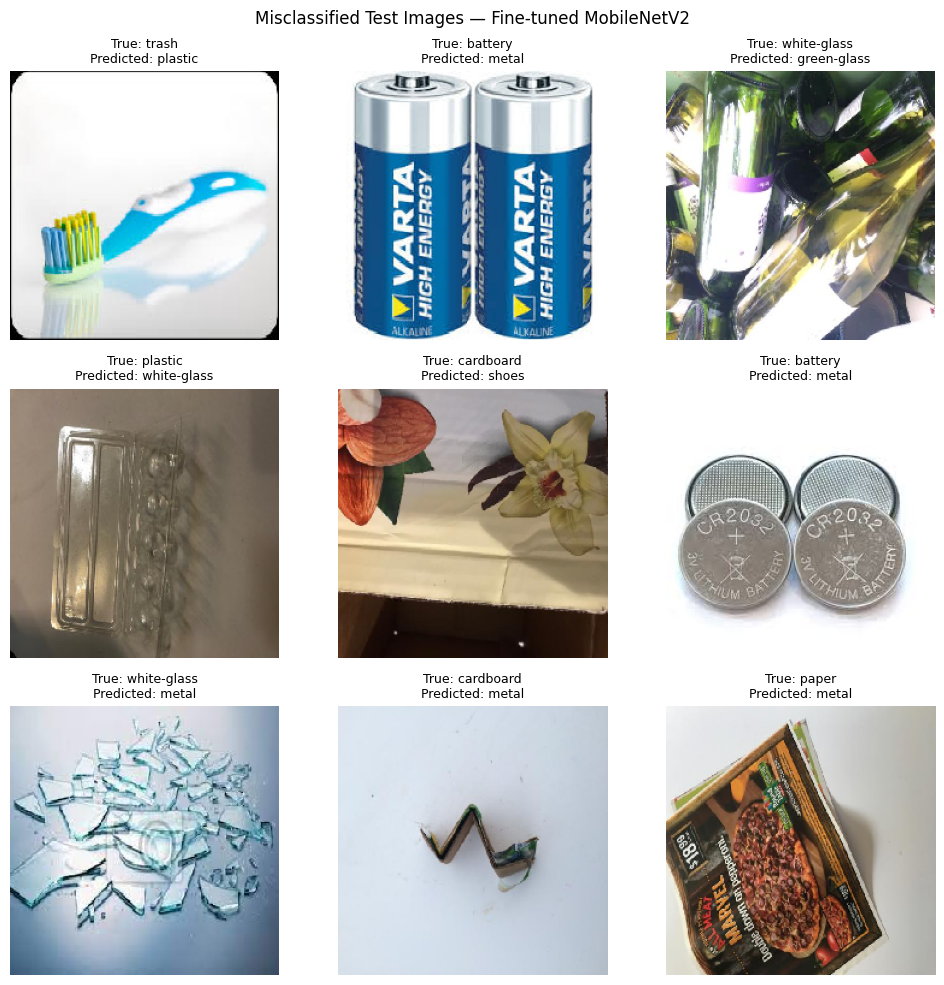

Displayed 9 randomly sampled errors.
Saved: outputs/errors.png


In [31]:

import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

os.makedirs("outputs", exist_ok=True)

# Ground-truth and final test predictions
yt = test_df["label"].map(class_to_idx).to_numpy(dtype=np.int32)
predictions = np.asarray(pred_ft_test, dtype=np.int32)

assert len(yt) == len(predictions) == len(test_df), \
    "Mismatch between test labels, predictions, and test dataframe."

# Identify incorrect predictions
rng = np.random.default_rng(42)
wrong_all = np.where(predictions != yt)[0]

print(f"Incorrect test predictions: {len(wrong_all)} / {len(yt)}")

if len(wrong_all) == 0:
    print("No incorrect predictions to display.")
else:
    n_show = min(9, len(wrong_all))
    wrong = rng.choice(wrong_all, size=n_show, replace=False)

    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    axes = axes.flatten()

    for k, i in enumerate(wrong):
        img = tf.keras.utils.load_img(
            str(test_df.iloc[i]["path"]),
            target_size=IMG_SIZE
        )

        axes[k].imshow(img)
        axes[k].axis("off")
        axes[k].set_title(
            f"True: {class_names[yt[i]]}\n"
            f"Predicted: {class_names[predictions[i]]}",
            fontsize=9
        )

    # Hide unused panels if fewer than nine errors exist
    for k in range(n_show, len(axes)):
        axes[k].axis("off")

    plt.suptitle("Misclassified Test Images — Fine-tuned MobileNetV2")
    plt.tight_layout()
    plt.savefig("outputs/errors.png", dpi=200, bbox_inches="tight")
    plt.show()

    print(f"Displayed {n_show} randomly sampled errors.")
    print("Saved: outputs/errors.png")


In [32]:

import time
import numpy as np
import tensorflow as tf

# Confirm the available hardware
gpus = tf.config.list_physical_devices("GPU")
print("Available GPUs:", gpus)

# Compiled inference function
@tf.function
def infer(x):
    return model(x, training=False)

# One synthetic image, with pixel values in the range [0, 255]
x = tf.constant(
    (np.random.rand(1, 224, 224, 3) * 255).astype(np.float32)
)

# Warm-up: allow graph tracing and initial execution to complete
for _ in range(20):
    infer(x).numpy()

# Measure 200 single-image inference runs
ts = []

for _ in range(200):
    t0 = time.perf_counter()
    infer(x).numpy()  # .numpy() synchronizes result retrieval
    ts.append((time.perf_counter() - t0) * 1000)

median_ms = float(np.median(ts))
p95_ms = float(np.percentile(ts, 95))

print(
    f"Median {median_ms:.2f} ms | "
    f"p95 {p95_ms:.2f} ms "
    "(compiled, batch 1, model only)"
)


Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Median 13.10 ms | p95 22.60 ms (compiled, batch 1, model only)


In [33]:

!git clone -q https://github.com/pedropro/TACO.git

import os
import json
import random
import requests
from collections import Counter

# Load TACO annotations
with open("TACO/data/annotations.json", "r") as f:
    ann = json.load(f)

# Keep images with at least 5 annotated objects
cnt = Counter(a["image_id"] for a in ann["annotations"])
cands = [
    im for im in ann["images"]
    if cnt[im["id"]] >= 5
    and (im.get("flickr_640_url") or im.get("flickr_url"))
]

print(len(cands), "images with >=5 annotated objects and a URL")

# Select up to 40 candidates reproducibly
random.seed(42)
pick = random.sample(cands, min(40, len(cands)))

os.makedirs("piles", exist_ok=True)
saved = 0

for im in pick:
    url = im.get("flickr_640_url") or im.get("flickr_url")

    try:
        r = requests.get(url, timeout=15)
        if r.status_code == 200 and len(r.content) > 5000:
            path = f"piles/taco_{im['id']}.jpg"
            with open(path, "wb") as f:
                f.write(r.content)
            saved += 1
            print("Downloaded:", path)
    except requests.RequestException as e:
        print(f"Download failed for image {im['id']}: {e}")

    if saved >= 25:
        break

print(f"\nSuccessfully downloaded {saved} TACO images.")


254 images with >=5 annotated objects and a URL
Downloaded: piles/taco_1029.jpg
Downloaded: piles/taco_135.jpg
Downloaded: piles/taco_46.jpg
Downloaded: piles/taco_1141.jpg
Downloaded: piles/taco_338.jpg
Downloaded: piles/taco_326.jpg
Downloaded: piles/taco_298.jpg
Downloaded: piles/taco_149.jpg
Downloaded: piles/taco_1140.jpg
Downloaded: piles/taco_121.jpg
Downloaded: piles/taco_1064.jpg
Downloaded: piles/taco_1486.jpg
Downloaded: piles/taco_1331.jpg
Downloaded: piles/taco_764.jpg
Downloaded: piles/taco_105.jpg
Downloaded: piles/taco_874.jpg
Downloaded: piles/taco_610.jpg
Downloaded: piles/taco_64.jpg
Downloaded: piles/taco_57.jpg
Downloaded: piles/taco_106.jpg
Downloaded: piles/taco_280.jpg
Downloaded: piles/taco_311.jpg
Downloaded: piles/taco_713.jpg
Downloaded: piles/taco_879.jpg
Downloaded: piles/taco_1488.jpg

Successfully downloaded 25 TACO images.


In [34]:

import os
import glob
import pandas as pd
from PIL import Image

G = 3
os.makedirs("tiles", exist_ok=True)

trows = []

for p in sorted(glob.glob("piles/*")):
    try:
        with Image.open(p) as source:
            im = source.convert("RGB")
    except Exception as e:
        print(f"Skipping unreadable image {p}: {e}")
        continue

    w, h = im.size
    base = os.path.splitext(os.path.basename(p))[0]

    for r in range(G):
        for c in range(G):
            # Integer boundaries ensure all pixels are covered
            tile = im.crop((
                c * w // G,
                r * h // G,
                (c + 1) * w // G,
                (r + 1) * h // G
            ))

            tp = f"tiles/{base}_r{r}c{c}.jpg"
            tile.save(tp, quality=95)

            trows.append({
                "photo": base,
                "tile_path": tp,
                "row": r,
                "col": c,
                "label": ""
            })

template = pd.DataFrame(trows)
template.to_csv("tile_labels_TEMPLATE.csv", index=False)

print(f"Tiles written: {len(template)}")
print(f"Source images processed: {template['photo'].nunique()}")
print("Template saved: tile_labels_TEMPLATE.csv")


Tiles written: 225
Source images processed: 25
Template saved: tile_labels_TEMPLATE.csv


In [35]:

import os
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output

T = pd.read_csv("tile_labels_TEMPLATE.csv")
T["label"] = T["label"].fillna("").astype(str)

# Labels for the binary confidence evaluation
opts = ["waste", "background", "uncertain"]

state = {"i": 0}
out = widgets.Output()
status = widgets.HTML()

def save_progress():
    T.to_csv("tile_labels_partial.csv", index=False)

def show():
    with out:
        clear_output(wait=True)
        i = state["i"]

        if i >= len(T):
            T.to_csv("tile_labels.csv", index=False)
            print("All tiles reviewed. Saved tile_labels.csv")
            return

        row = T.iloc[i]
        img = Image.open(row["tile_path"]).convert("RGB")

        plt.figure(figsize=(5, 5))
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"Tile {i + 1}/{len(T)} | {row['photo']}")
        plt.show()

        print("Current label:", row["label"] or "(unlabeled)")

    labeled = (T["label"] != "").sum()
    status.value = (
        f"<b>Progress:</b> {labeled}/{len(T)} labeled "
        f"| <b>Current tile:</b> {min(state['i'] + 1, len(T))}/{len(T)}"
    )

def pick(lbl):
    def handler(_):
        i = state["i"]
        if i >= len(T):
            return

        T.loc[i, "label"] = lbl
        save_progress()
        state["i"] = min(i + 1, len(T))
        show()
    return handler

def back(_):
    state["i"] = max(0, state["i"] - 1)
    show()

buttons = []
for label in opts:
    b = widgets.Button(
        description=label,
        layout=widgets.Layout(width="130px", height="38px")
    )
    b.on_click(pick(label))
    buttons.append(b)

back_btn = widgets.Button(
    description="Back",
    button_style="warning",
    layout=widgets.Layout(width="100px", height="38px")
)
back_btn.on_click(back)

display(status)
display(widgets.HBox(buttons))
display(back_btn, out)
show()


HTML(value='')

Button(button_style='warning', description='Back', layout=Layout(height='38px', width='100px'), style=ButtonSt…

Output()

In [36]:

import os
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

os.makedirs("outputs", exist_ok=True)

# 1. Load and clean tile labels
lab = pd.read_csv("tile_labels.csv")
lab["label"] = lab["label"].fillna("").astype(str).str.strip().str.lower()
lab = lab[lab["label"] != ""].copy()

name2id = {name: i for i, name in enumerate(class_names)}

# Tiles labeled with one of the model's 12 material classes
valid = lab[lab["label"].isin(name2id)].copy()
other = lab[lab["label"].isin(["waste", "background", "uncertain", "mixed"])].copy()

valid["y"] = valid["label"].map(name2id).astype(int)

print(
    "Dominant-material tiles:", len(valid),
    "| binary/mixed/uncertain tiles:", len(other),
    "| photos:", lab["photo"].nunique()
)

# 2. Predict on tiles
def predict_tiles(df_tiles):
    if len(df_tiles) == 0:
        return np.array([], dtype=int), np.array([])

    tmp = pd.DataFrame({
        "path": df_tiles["tile_path"].astype(str).values,
        "label": np.zeros(len(df_tiles), dtype=np.int32)
    })
    probs = model.predict(make_ds(tmp), verbose=0)
    return probs.argmax(axis=1), probs.max(axis=1)

if len(valid):
    valid["pred"], valid["conf"] = predict_tiles(valid)

    print(
        "Tile material accuracy:",
        round(accuracy_score(valid["y"], valid["pred"]), 4)
    )
    print(
        "Reference single-image test accuracy:",
        round(res_ft_test["accuracy"], 4)
    )
    print(
        "Mean confidence when correct:",
        round(valid.loc[valid["pred"] == valid["y"], "conf"].mean(), 3)
        if (valid["pred"] == valid["y"]).any() else "N/A",
        "| when wrong:",
        round(valid.loc[valid["pred"] != valid["y"], "conf"].mean(), 3)
        if (valid["pred"] != valid["y"]).any() else "N/A"
    )

    print("\nTile material classification report:")
    present = sorted(valid["y"].unique())
    print(classification_report(
        valid["y"], valid["pred"],
        labels=present,
        target_names=[class_names[i] for i in present],
        digits=3,
        zero_division=0
    ))

    # Composition error per photo, only for material-labeled tiles
    errs = []
    for photo, g in valid.groupby("photo"):
        true_comp = g["y"].value_counts(normalize=True).reindex(
            range(NUM_CLASSES), fill_value=0
        )
        pred_comp = g["pred"].value_counts(normalize=True).reindex(
            range(NUM_CLASSES), fill_value=0
        )
        errs.append(0.5 * np.abs(true_comp - pred_comp).sum())

    print(
        "Mean composition error per photo:",
        round(float(np.mean(errs)), 3),
        "over", len(errs), "photos"
    )

    valid.to_csv("outputs/pile_tile_results.csv", index=False)
    print("Saved outputs/pile_tile_results.csv")
else:
    print("No material-class tiles found. Check tile_labels.csv labels.")

# 3. Confidence-based error detection AUROC on material-labeled tiles
# Positive = prediction is correct; score = maximum softmax confidence
if len(valid):
    correct = (valid["pred"].to_numpy() == valid["y"].to_numpy()).astype(int)

    if len(np.unique(correct)) == 2:
        auroc_error = roc_auc_score(correct, valid["conf"])
        print(f"AUROC (correct vs. incorrect tile predictions): {auroc_error:.4f}")
    else:
        print("Error-detection AUROC unavailable: only correct or only incorrect predictions.")

# 4. Report other tile labels separately; do not treat them as material classes
if len(other):
    other = other.copy()
    other["pred"], other["conf"] = predict_tiles(other)
    print("\nOther tile labels:")
    print(other["label"].value_counts().to_string())
    print("Mean maximum softmax confidence for these tiles:",
          round(float(other["conf"].mean()), 3))
    other.to_csv("outputs/pile_other_tile_results.csv", index=False)
    print("Saved outputs/pile_other_tile_results.csv")


Dominant-material tiles: 0 | binary/mixed/uncertain tiles: 225 | photos: 25
No material-class tiles found. Check tile_labels.csv labels.


/usr/local/lib/python3.13/dist-packages/pandas/core/base.py:662: RuntimeWarning: invalid value encountered in cast
  result = np.asarray(values, dtype=dtype)



Other tile labels:
label
background    176
waste          46
uncertain       3
Mean maximum softmax confidence for these tiles: 0.715
Saved outputs/pile_other_tile_results.csv


In [38]:

import numpy as np
import pandas as pd
import tensorflow as tf

# Predict tiles directly without requiring class labels in the dataset
def predict_tiles(df_tiles):
    if len(df_tiles) == 0:
        return np.array([], dtype=int), np.array([], dtype=float)

    paths = df_tiles["tile_path"].astype(str).to_numpy()

    ds = tf.data.Dataset.from_tensor_slices(paths)

    def load_tile(path):
        img = tf.io.read_file(path)
        img = tf.io.decode_image(
            img, channels=3, expand_animations=False
        )
        img = tf.image.resize(img, IMG_SIZE)
        img = tf.cast(img, tf.float32)
        img.set_shape((224, 224, 3))
        return img

    ds = ds.map(
        load_tile, num_parallel_calls=tf.data.AUTOTUNE
    ).batch(BATCH).prefetch(tf.data.AUTOTUNE)

    probs = model.predict(ds, verbose=0)
    return probs.argmax(axis=1), probs.max(axis=1)


# Ensure valid contains the model's known material classes
lab["label"] = lab["label"].fillna("").str.strip().str.lower()
name2id = {name: i for i, name in enumerate(class_names)}

valid = lab[lab["label"].isin(name2id)].copy()
valid["y"] = valid["label"].map(name2id).astype(int)

valid["pred"], valid["conf"] = predict_tiles(valid)

print("Columns:", valid.columns.tolist())
print("Material-class tiles:", len(valid))
print(valid[["label", "y", "pred", "conf"]].head())


Columns: ['photo', 'tile_path', 'row', 'col', 'label', 'y', 'pred', 'conf']
Material-class tiles: 0
Empty DataFrame
Columns: [label, y, pred, conf]
Index: []


In [39]:

import numpy as np
import pandas as pd
from statsmodels.stats.proportion import proportion_confint

# Predict confidence for background and mixed tiles
bg_only = lab[lab["label"] == "background"].copy()
mx = lab[lab["label"] == "mixed"].copy()

_, c_bg = predict_tiles(bg_only)
_, c_mx = predict_tiles(mx)

print(
    f"Background tiles: {len(bg_only)} | "
    f"Mixed tiles: {len(mx)} | "
    f"Material-class tiles: {len(valid)}"
)

# Confidence-threshold analysis
rows = []

for threshold in [0.5, 0.7, 0.9]:
    kept = valid[valid["conf"] >= threshold]

    rows.append({
        "threshold": threshold,
        "background_high_conf_rate": (
            float(np.mean(c_bg >= threshold)) if len(c_bg) else np.nan
        ),
        "mixed_high_conf_rate": (
            float(np.mean(c_mx >= threshold)) if len(c_mx) else np.nan
        ),
        "material_tiles_retained": (
            len(kept) / len(valid) if len(valid) else np.nan
        ),
        "retained_tile_accuracy": (
            float((kept["pred"] == kept["y"]).mean())
            if len(kept) else np.nan
        ),
        "retained_tile_count": len(kept)
    })

results_threshold = pd.DataFrame(rows)

print("\nConfidence-threshold results:")
print(results_threshold.round(3).to_string(index=False))

results_threshold.to_csv(
    "outputs/tile_confidence_thresholds.csv", index=False
)
print("\nSaved outputs/tile_confidence_thresholds.csv")

# Wilson 95% confidence interval for material-class tile accuracy
if len(valid):
    correct = (valid["pred"].to_numpy() == valid["y"].to_numpy())
    k = int(correct.sum())
    n = len(correct)

    ci_low, ci_high = proportion_confint(k, n, method="wilson")

    print(
        f"\nMaterial-tile accuracy: {k}/{n} = {k/n:.4f}"
        f"\nWilson 95% CI: [{ci_low:.3f}, {ci_high:.3f}]"
    )
else:
    print("Cannot calculate accuracy: no material-class tiles.")


Background tiles: 176 | Mixed tiles: 0 | Material-class tiles: 0

Confidence-threshold results:
 threshold  background_high_conf_rate  mixed_high_conf_rate  material_tiles_retained  retained_tile_accuracy  retained_tile_count
       0.5                      0.773                   NaN                      NaN                     NaN                    0
       0.7                      0.545                   NaN                      NaN                     NaN                    0
       0.9                      0.301                   NaN                      NaN                     NaN                    0

Saved outputs/tile_confidence_thresholds.csv
Cannot calculate accuracy: no material-class tiles.


In [40]:

# Tiles not labeled as one of the 12 material classes
bg = lab[~lab["label"].isin(name2id)].copy()

_, bconf = predict_tiles(bg)

print("Non-class / mixed / background tiles:", len(bg))

if len(bg) == 0:
    print("No such tiles found. Check lab['label'].value_counts().")
else:
    for t in [0.5, 0.7, 0.9]:
        count = int((bconf >= t).sum())
        rate = count / len(bconf)
        print(
            f"Confidence >= {t}: {count}/{len(bconf)} "
            f"({rate:.1%})"
        )


Non-class / mixed / background tiles: 225
Confidence >= 0.5: 175/225 (77.8%)
Confidence >= 0.7: 123/225 (54.7%)
Confidence >= 0.9: 66/225 (29.3%)


In [42]:

print("Tile-label counts:")
print(lab["label"].value_counts(dropna=False))

print("\nSource photographs:", lab["photo"].nunique())
print("Material-class tiles:", len(valid))
print("Background-only tiles:", len(bg_only))
print("Mixed tiles:", len(mx))


Tile-label counts:
label
background    176
waste          46
uncertain       3
Name: count, dtype: int64

Source photographs: 25
Material-class tiles: 0
Background-only tiles: 176
Mixed tiles: 0


In [41]:

from sklearn.metrics import roc_auc_score
import numpy as np

# 1. AUROC: does maximum softmax confidence distinguish
# correctly classified from incorrectly classified test images?
pt = model.predict(test_ds, verbose=0)

y_true = test_df["label"].map(class_to_idx).to_numpy(dtype=int)
y_pred = pt.argmax(axis=1)
confidence = pt.max(axis=1)
correct = (y_pred == y_true)

if len(np.unique(correct)) == 2:
    auc_correctness = roc_auc_score(correct.astype(int), confidence)
    print("AUROC correct vs wrong (test set):", round(auc_correctness, 3))
else:
    print("AUROC correct vs wrong: undefined; test set has only one outcome.")

# 2. AUROC: class-labeled material tiles vs background-only tiles
# valid must have 'conf'; c_bg must come from background-only tiles.
class_scores = valid["conf"].to_numpy(dtype=float)
background_scores = np.asarray(c_bg, dtype=float)

if len(class_scores) and len(background_scores):
    yy = np.r_[
        np.ones(len(class_scores), dtype=int),
        np.zeros(len(background_scores), dtype=int)
    ]
    ss = np.r_[class_scores, background_scores]

    auc_tiles = roc_auc_score(yy, ss)
    print("AUROC class tiles vs background tiles:", round(auc_tiles, 3))
    print("Material tiles:", len(class_scores), "| Background tiles:", len(background_scores))
else:
    print("Tile AUROC unavailable: one or both groups are empty.")


AUROC correct vs wrong (test set): 0.938
Tile AUROC unavailable: one or both groups are empty.


In [43]:

print("All tile labels:")
print(lab["label"].value_counts(dropna=False))

print("\nMaterial-class tiles:", len(valid))
print("Background-only tiles:", len(bg_only))
print("Mixed tiles:", len(mx))
print("Background confidence scores:", len(c_bg))

print("\nExpected material labels:")
print(class_names)


All tile labels:
label
background    176
waste          46
uncertain       3
Name: count, dtype: int64

Material-class tiles: 0
Background-only tiles: 176
Mixed tiles: 0
Background confidence scores: 176

Expected material labels:
['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']


In [44]:

from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd

# Keep only reliable binary labels; exclude uncertain tiles
binary = lab[lab["label"].isin(["waste", "background"])].copy()

waste_tiles = binary[binary["label"] == "waste"].copy()
background_tiles = binary[binary["label"] == "background"].copy()

# Predict maximum softmax confidence for both groups
_, waste_conf = predict_tiles(waste_tiles)
_, background_conf = predict_tiles(background_tiles)

# Positive class = waste; score = maximum softmax confidence
y_binary = np.r_[
    np.ones(len(waste_conf), dtype=int),
    np.zeros(len(background_conf), dtype=int)
]
scores = np.r_[waste_conf, background_conf]

if len(waste_conf) and len(background_conf):
    tile_auc = roc_auc_score(y_binary, scores)

    print(f"Waste tiles: {len(waste_conf)}")
    print(f"Background tiles: {len(background_conf)}")
    print(f"Mean confidence on waste: {waste_conf.mean():.3f}")
    print(f"Mean confidence on background: {background_conf.mean():.3f}")
    print(f"AUROC waste vs background: {tile_auc:.3f}")

    for threshold in [0.5, 0.7, 0.9]:
        print(
            f"Confidence >= {threshold}: "
            f"waste={np.mean(waste_conf >= threshold):.1%}, "
            f"background={np.mean(background_conf >= threshold):.1%}"
        )

    pd.DataFrame({
        "label": ["waste"] * len(waste_conf)
                 + ["background"] * len(background_conf),
        "max_softmax_confidence": scores
    }).to_csv("outputs/taco_binary_tile_confidence.csv", index=False)

    print("Saved outputs/taco_binary_tile_confidence.csv")
else:
    print("AUROC cannot be calculated: one group is empty.")


Waste tiles: 46
Background tiles: 176
Mean confidence on waste: 0.706
Mean confidence on background: 0.716
AUROC waste vs background: 0.483
Confidence >= 0.5: waste=80.4%, background=77.3%
Confidence >= 0.7: waste=54.3%, background=54.5%
Confidence >= 0.9: waste=26.1%, background=30.1%
Saved outputs/taco_binary_tile_confidence.csv
